# DS608 — Technology pillar: UN Comtrade full pull

**Pipeline:** raw Comtrade ZIPs → filter HS technology basket → harmonise reporters → aggregate bilateral imports → US–China technology orientation → processed country-year tables.

$$TechnologyOrientation_{it} = \frac{US_{it} - China_{it}}{US_{it} + China_{it}}$$

`-1` = fully China-sourced, `0` = equal, `+1` = fully US-sourced, within the bilateral technology-goods comparison only. This is **not** a geopolitical alignment measure.

All processing logic is in `src/data/process_comtrade_technology.py`. This notebook runs it step by step and shows the audit output. Run it from the repository root, or from `notebooks/`, which the path cell handles.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.data import process_comtrade_technology as tech

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
import os
# TECH_RAW_DIR lets you test the notebook on another folder; outputs are only written for the default raw folder.
RAW_DIR = Path(os.environ.get("TECH_RAW_DIR", tech.RAW_DIR))
WRITE = RAW_DIR == tech.RAW_DIR
print("Raw directory:", RAW_DIR, "| write outputs:", WRITE)

Raw directory: /home/claude/ds608-project-us-china-closeness-index/data/raw/un_comtrade/technology | write outputs: True


## Step 1 — Inspect and load the ZIP files

In [2]:
zip_paths = tech.discover_zip_files(RAW_DIR)
inventory = tech.inspect_zip_files(zip_paths)
inventory

,zip_file,member,uncompressed_bytes,compressed_bytes
0,190b64df-batchid-25642f40-fafd-4fb7-b6b8-eed66...,batchid-25642f40-fafd-4fb7-b6b8-eed664a7bdc0.txt,314593,42542
1,3af4154e-batchid-e130647f-70b8-4876-99e0-16fa7...,batchid-e130647f-70b8-4876-99e0-16fa77b5ffed.txt,288284,42622
2,49566102-batchid-bc622113-0d31-4f59-b2ed-30d04...,batchid-bc622113-0d31-4f59-b2ed-30d043f64cb7.txt,338662,49882
3,api_p156_2023.zip,api_p156_2023.txt,276554,21673
4,api_p842_2014.zip,api_p842_2014.txt,251087,18095
5,api_p842_2015.zip,api_p842_2015.txt,255856,19161
6,api_p842_2016.zip,api_p842_2016.txt,258378,19598
7,api_p842_2017.zip,api_p842_2017.txt,269821,21689
8,api_p842_2018.zip,api_p842_2018.txt,264554,21338
9,api_p842_2019.zip,api_p842_2019.txt,259963,20336


In [3]:
raw, inventory = tech.load_raw_comtrade(RAW_DIR)
summary = tech.summarise_raw(raw, inventory)
for k, v in summary.items():
    print(f"{k:>18}: {v}")

         zip_files: 17
 data_files_loaded: 17
     empty_batches: []
              rows: 16094
           columns: 47
          year_min: 2014
          year_max: 2025
     years_present: [2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]
  unique_reporters: 190
     partner_codes: ['156', '842']
          hs_codes: ['8471', '8517', '8541', '8542']
        flow_codes: ['M']
         mot_codes: ['0']


Rows per year per batch. A year that shows up in more than one batch means the batches overlap.

In [4]:
tech.year_batch_matrix(raw)

source_zip,190b64df-batchid-25642f40-fafd-4fb7-b6b8-eed664a7bdc0.zip,3af4154e-batchid-e130647f-70b8-4876-99e0-16fa77b5ffed.zip,49566102-batchid-bc622113-0d31-4f59-b2ed-30d043f64cb7.zip,api_p156_2023.zip,api_p842_2014.zip,api_p842_2015.zip,api_p842_2016.zip,api_p842_2017.zip,api_p842_2018.zip,api_p842_2019.zip,api_p842_2020.zip,api_p842_2021.zip,api_p842_2022.zip,api_p842_2023.zip,api_p842_2024.zip,api_p842_2025.zip,dbe40923-batchid-717a87a4-1114-4dc2-aaa4-185e2291239c.zip
refYear,,,,,,,,,,,,,,,,,
2014,669,0,0,0,648,0,0,0,0,0,0,0,0,0,0,0,0
2015,676,0,0,0,0,658,0,0,0,0,0,0,0,0,0,0,0
2016,689,0,0,0,0,0,662,0,0,0,0,0,0,0,0,0,0
2017,0,0,705,0,0,0,0,678,0,0,0,0,0,0,0,0,0
2018,0,0,701,0,0,0,0,0,662,0,0,0,0,0,0,0,0
2019,0,0,678,0,0,0,0,0,0,649,0,0,0,0,0,0,0
2020,0,0,0,0,0,0,0,0,0,0,640,0,0,0,0,0,663
2021,0,673,0,0,0,0,0,0,0,0,0,645,0,0,0,0,673
2022,0,0,0,0,0,0,0,0,0,0,0,0,636,0,0,0,654


**Findings from Step 1**

* All four ZIPs load. Each holds exactly one tab-delimited, UTF-8-BOM `.txt` file.
* **Partner codes found: `156` (China) only.** The pull contains **no United States (842) partner rows**, so the US side of the score is missing for every country-year.
* **2021 is in two batches** (`717a87a4…` and `e130647f…`). Step 4 handles it.
* **2023 is in no batch.** It stays in the panel as `year_not_in_source_pull`.
* Flow (`M`), mode of transport (`0`) and HS codes (8471/8517/8541/8542) are already restricted at download time.

## Step 2 — Validate columns and build the country crosswalk

In [5]:
column_report = tech.validate_columns(raw)
column_report

,column,present,non_blank_rows,blank_rows,fill_rate
0,refYear,True,16094,0,1.0000
1,reporterCode,True,16094,0,1.0000
2,reporterISO,True,8226,7868,0.5111
3,reporterDesc,True,8226,7868,0.5111
4,flowCode,True,16094,0,1.0000
5,partnerCode,True,16094,0,1.0000
6,partnerISO,True,8226,7868,0.5111
7,partnerDesc,True,8226,7868,0.5111
8,cmdCode,True,16094,0,1.0000
9,motCode,True,16094,0,1.0000


All required columns exist, but `reporterISO`, `reporterDesc`, `partnerISO` and `partnerDesc` are **blank in every row** of this bulk download. The crosswalk resolves each code in this order:

1. source ISO and name fields, when they are filled in;
2. a short, documented list of Comtrade-specific M49 codes that differ from ISO 3166 numeric (251, 490, 579, 699, 757, 842);
3. the ISO 3166-1 numeric standard (via `pycountry`).

Any code that none of these resolve is flagged `unresolved`. The table is saved to `data/reference/comtrade_country_crosswalk.csv` for reuse by other pillars.

In [6]:
crosswalk = tech.build_country_crosswalk(raw)
print(crosswalk["mapping_method"].value_counts().to_string())
print("Unresolved codes:", crosswalk.loc[crosswalk.mapping_method == "unresolved", "comtrade_code"].tolist())
crosswalk[crosswalk.mapping_method != "iso3166_numeric"]

mapping_method
source_field    190
Unresolved codes: []


,comtrade_code,country_iso3,country,mapping_method,is_iso3166,note
0,4,AFG,Afghanistan,source_field,True,
1,8,ALB,Albania,source_field,True,
2,12,DZA,Algeria,source_field,True,
3,20,AND,Andorra,source_field,True,
4,24,AGO,Angola,source_field,True,
...,...,...,...,...,...,...
185,858,URY,Uruguay,source_field,True,
186,860,UZB,Uzbekistan,source_field,True,
187,882,WSM,Samoa,source_field,True,
188,887,YEM,Yemen,source_field,True,


Code 490 (*Other Asia, nes*, i.e. Taiwan) uses Comtrade's pseudo-ISO code `S19`, so it is marked `is_iso3166 = False`. Check how the other pillars key this economy before merging.

## Step 3 — Apply the accepted trade filters

In [7]:
filtered, filter_log = tech.apply_trade_filters(raw)
filter_log

,filter_step,rows_remaining
0,raw,16094
1,flowCode == M,16094
2,motCode == 0,16094
3,"partnerCode in {156, 842}",16094
4,cmdCode in HS basket,16094


## Step 4 — Duplicate audit (reporter × year × partner × HS)

In [8]:
deduped, dup_audit = tech.audit_and_resolve_duplicates(filtered)
dup_audit.summary

,stage,rows,key_duplicate_rows
0,after filters,16094,1346
1,A: drop exact cross-batch copies,15421,0
2,B: keep total-dimension rows,15421,0


In [9]:
dup_audit.cross_batch_detail

,refYear,source_zip,rows
0,2021,3af4154e-batchid-e130647f-70b8-4876-99e0-16fa7...,673
1,2021,dbe40923-batchid-717a87a4-1114-4dc2-aaa4-185e2...,673


**Cause:** every duplicate at `reporterCode × refYear × partnerCode × cmdCode` comes from the 2021 overlap between two batches. Each pair is identical in **all 47 Comtrade columns**, including `primaryValue`, `customsCode = C00`, `partner2Code = 0`, `mosCode = 0`, `motCode = 0` and the classification. They are the same record downloaded twice, so one copy is kept.

No duplicates remain that differ by customs procedure, secondary partner, mode of supply or classification. The stage-B rule (keep only the total row: `C00`, partner2 `0`, MoS `0`, original classification) is still in the code for future pulls. If any duplicate survives that rule, the pipeline **stops instead of dropping it**.

In [10]:
key = ["reporterCode", "refYear", "partnerCode", "cmdCode"]
assert not deduped.duplicated(key).any()
print("Rows after de-duplication:", len(deduped))

Rows after de-duplication: 15421


## Step 5 — Harmonise labels

In [11]:
labelled = tech.harmonise_labels(deduped, crosswalk)
anchors = labelled[labelled.reporter_code.isin(tech.ANCHOR_REPORTER_CODES)]
print("Anchor reporters present (excluded from scoring, as in the total-trade pillar):",
      anchors.groupby(["reporter_code", "country"]).size().to_dict())
labelled.head()

Anchor reporters present (excluded from scoring, as in the total-trade pillar): {(156, 'China'): 96, (842, 'USA'): 48}


,reporter_code,country_iso3,country,year,partner_code,partner,hs_code,tech_category,value_usd,classification,is_reported,is_aggregate,legacy_estimation_flag,source_zip
0,8,ALB,Albania,2014,156,China,8471,Computers and data-processing equipment,2.714497e+06,H4,True,False,0,190b64df-batchid-25642f40-fafd-4fb7-b6b8-eed66...
1,12,DZA,Algeria,2014,156,China,8471,Computers and data-processing equipment,4.046264e+08,H4,True,False,0,190b64df-batchid-25642f40-fafd-4fb7-b6b8-eed66...
2,20,AND,Andorra,2014,156,China,8471,Computers and data-processing equipment,8.988132e+05,H4,False,True,2,190b64df-batchid-25642f40-fafd-4fb7-b6b8-eed66...
3,24,AGO,Angola,2014,156,China,8471,Computers and data-processing equipment,8.629049e+06,H4,False,True,2,190b64df-batchid-25642f40-fafd-4fb7-b6b8-eed66...
4,28,ATG,Antigua and Barbuda,2014,156,China,8471,Computers and data-processing equipment,1.959750e+06,H3,True,False,0,190b64df-batchid-25642f40-fafd-4fb7-b6b8-eed66...


## Step 6 — Category-level bilateral data

In [12]:
year_range = list(range(summary["year_min"], summary["year_max"] + 1))
components = tech.build_category_components(labelled, crosswalk, year_range)
print(components.shape)
print(components["data_status"].value_counts().to_string())
components.head(8)

(9024, 11)
data_status
complete         7448
missing_both     1195
missing_us        313
missing_china      68


partner_code,country_iso3,country,reporter_code,year,hs_code,tech_category,china_imports,us_imports,category_orientation_score,data_complete,data_status
0,ABW,Aruba,533,2014,8471,Computers and data-processing equipment,6534.0,9524474.0,0.998629,True,complete
1,ABW,Aruba,533,2014,8517,Telecommunications equipment,1238425.0,22855903.0,0.897202,True,complete
2,ABW,Aruba,533,2014,8541,Semiconductor devices,1689223.0,943011.0,-0.283490,True,complete
3,ABW,Aruba,533,2014,8542,Integrated circuits,929.0,414277.0,0.995525,True,complete
4,ABW,Aruba,533,2015,8471,Computers and data-processing equipment,2380.0,8723150.0,0.999454,True,complete
5,ABW,Aruba,533,2015,8517,Telecommunications equipment,179443.0,24616035.0,0.985526,True,complete
6,ABW,Aruba,533,2015,8541,Semiconductor devices,355625.0,825629.0,0.397886,True,complete
7,ABW,Aruba,533,2015,8542,Integrated circuits,NaN,289352.0,NaN,False,missing_china


## Step 7 — Combined technology score

Totals are summed over the **matched basket**: the HS categories where *both* partners report a value. This means a category missing on one side is never treated as zero. `n_categories_matched` records how many of the four categories enter the score. `data_complete` is True only when all four do.

In [13]:
combined = tech.build_combined_orientation(components)
print(combined["data_status"].value_counts().to_string())
print("Scored country-years:", combined["tech_orientation_score"].notna().sum())
combined.head(8)

data_status
complete               1719
no_data                 282
partial_basket          230
missing_us               21
missing_china             3
no_matched_category       1
Scored country-years: 1949


,country_iso3,country,reporter_code,year,china_tech_imports,us_tech_imports,tech_orientation_score,data_complete,data_status,n_categories_matched,n_categories_china,n_categories_us,china_tech_imports_reported,us_tech_imports_reported
0,ABW,Aruba,533,2014,2935111.000,3.373766e+07,0.839930,True,complete,4,4,4,2935111.000,3.373766e+07
1,ABW,Aruba,533,2015,537448.000,3.416481e+07,0.969025,False,partial_basket,3,3,4,537448.000,3.445417e+07
2,ABW,Aruba,533,2016,655860.600,1.754452e+07,0.927929,False,partial_basket,2,2,4,655860.600,2.379603e+07
3,ABW,Aruba,533,2017,462427.918,2.928175e+07,0.968906,True,complete,4,4,4,462427.918,2.928175e+07
4,ABW,Aruba,533,2018,4223198.747,2.668821e+07,0.726755,True,complete,4,4,4,4223198.747,2.668821e+07
5,ABW,Aruba,533,2019,1289707.779,2.676654e+07,0.908063,True,complete,4,4,4,1289707.779,2.676654e+07
6,ABW,Aruba,533,2020,893465.893,2.364700e+07,0.927184,True,complete,4,4,4,893465.893,2.364700e+07
7,ABW,Aruba,533,2021,805506.134,2.407057e+07,0.935238,True,complete,4,4,4,805506.134,2.407057e+07


## Step 8 — Coverage audit

In [14]:
coverage = tech.coverage_by_year(combined, year_range)
coverage

,year,year_in_source_pull,countries_in_panel,countries_with_any_data,countries_with_china_data,countries_with_us_data,complete_observations,scored_observations,missing_observations,min_score,max_score,mean_score,n_near_minus_1,n_near_plus_1
0,2014,True,188,170,170,168,142,168,46,-0.998929,0.994596,-0.566952,17,2
1,2015,True,188,173,172,171,146,170,42,-0.999637,0.984049,-0.592786,16,3
2,2016,True,188,175,174,173,146,172,42,-0.999882,0.992967,-0.585770,16,3
3,2017,True,188,178,178,177,149,177,39,-0.999701,0.980495,-0.574266,18,3
4,2018,True,188,176,176,174,148,174,40,-0.999990,0.997926,-0.638713,30,3
5,2019,True,188,170,169,168,147,167,41,-0.999072,0.985544,-0.643987,27,2
6,2020,True,188,166,166,164,146,164,42,-0.998955,0.991083,-0.645298,27,2
7,2021,True,188,167,167,166,153,166,35,-0.997215,0.989557,-0.672990,33,2
8,2022,True,188,165,165,163,147,162,41,-0.997464,0.923568,-0.687507,35,0
9,2023,True,188,165,165,162,146,162,42,-0.997979,0.921324,-0.668109,35,0


In [15]:
flags = tech.qa_flags(combined, components, summary["years_present"])
flags.groupby("flag").size().rename("n").to_frame()

,n
flag,
large_yoy_change,55
near_bound_score,321
small_category_value,705
small_total_value,348
suspicious_gap,13
us_partner_always_missing,1


In [16]:
flags[flags.flag == "suspicious_gap"]

,country_iso3,country,year,flag,detail
377,BTN,Bhutan,<NA>,suspicious_gap,"no data in [2021, 2024] between 2016-2025"
378,COM,Comoros,<NA>,suspicious_gap,no data in [2024] between 2014-2025
379,CYM,Cayman Isds,<NA>,suspicious_gap,"no data in [2016, 2017, 2018, 2019] between 20..."
380,DZA,Algeria,<NA>,suspicious_gap,"no data in [2018, 2019, 2020, 2021, 2022, 2023..."
381,GHA,Ghana,<NA>,suspicious_gap,no data in [2020] between 2014-2025
382,IRQ,Iraq,<NA>,suspicious_gap,"no data in [2015, 2016, 2017, 2018, 2019, 2020..."
383,KAZ,Kazakhstan,<NA>,suspicious_gap,"no data in [2020, 2021, 2022] between 2014-2025"
384,KIR,Kiribati,<NA>,suspicious_gap,no data in [2019] between 2014-2021
385,LKA,Sri Lanka,<NA>,suspicious_gap,no data in [2018] between 2014-2025
386,LSO,Lesotho,<NA>,suspicious_gap,no data in [2017] between 2014-2024


In [17]:
flags[flags.flag == "small_total_value"].head(15)

,country_iso3,country,year,flag,detail
390,ABW,Aruba,2015,small_total_value,"China tech imports US$537,448 < US$1,000,000"
391,ABW,Aruba,2016,small_total_value,"China tech imports US$655,861 < US$1,000,000"
392,ABW,Aruba,2017,small_total_value,"China tech imports US$462,428 < US$1,000,000"
393,ABW,Aruba,2020,small_total_value,"China tech imports US$893,466 < US$1,000,000"
394,ABW,Aruba,2021,small_total_value,"China tech imports US$805,506 < US$1,000,000"
395,AFG,Afghanistan,2015,small_total_value,"China tech imports US$725,122 < US$1,000,000"
396,AFG,Afghanistan,2017,small_total_value,"US tech imports US$269,202 < US$1,000,000"
397,AFG,Afghanistan,2018,small_total_value,"US tech imports US$371 < US$1,000,000"
398,ALB,Albania,2014,small_total_value,"US tech imports US$927,636 < US$1,000,000"
399,ALB,Albania,2017,small_total_value,"US tech imports US$983,809 < US$1,000,000"


Nothing flagged above is removed or changed. The flags go to `outputs/tables/technology_qa_flags.csv` for review. Large year-to-year changes and near-±1 checks run automatically once US data is present; at the moment there are no scores for them to check.

## Step 9 — Long-form pillar panel

In [18]:
long = tech.build_pillar_long(combined)
print(long.shape)
long.head()

(2256, 8)


,country_iso3,country,year,pillar,indicator,score,data_status,source
0,ABW,Aruba,2014,technology,technology_goods_trade_orientation,0.839930,complete,UN Comtrade
1,ABW,Aruba,2015,technology,technology_goods_trade_orientation,0.969025,partial_basket,UN Comtrade
2,ABW,Aruba,2016,technology,technology_goods_trade_orientation,0.927929,partial_basket,UN Comtrade
3,ABW,Aruba,2017,technology,technology_goods_trade_orientation,0.968906,complete,UN Comtrade
4,ABW,Aruba,2018,technology,technology_goods_trade_orientation,0.726755,complete,UN Comtrade


## Write outputs

In [19]:
tables = tech.run_pipeline(RAW_DIR, write=WRITE, verbose=True)
for p in ["data/processed/technology_trade_components.csv",
          "data/processed/technology_trade_orientation.csv",
          "data/processed/technology_pillar_long.csv",
          "data/interim/comtrade_technology_filtered.parquet",
          "data/reference/comtrade_country_crosswalk.csv"]:
    print(f"{(ROOT / p).stat().st_size:>10,} bytes  {p}")

Step 1 - raw load: {"zip_files": 17, "data_files_loaded": 17, "empty_batches": [], "rows": 16094, "columns": 47, "year_min": 2014, "year_max": 2025, "years_present": [2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025], "unique_reporters": 190, "partner_codes": ["156", "842"], "hs_codes": ["8471", "8517", "8541", "8542"], "flow_codes": ["M"], "mot_codes": ["0"]}


Step 2 - crosswalk: 190 codes, 0 unresolved
Step 3 - rows after filters: 16094
Step 4 - removed 673 exact cross-batch copies; 15421 rows remain
Step 5 - anchor reporters excluded from scoring: [156, 842] (144 rows)


Steps 6-9 - 2256 country-years, 1949 scored
   963,519 bytes  data/processed/technology_trade_components.csv
   244,176 bytes  data/processed/technology_trade_orientation.csv
   234,401 bytes  data/processed/technology_pillar_long.csv
   171,041 bytes  data/interim/comtrade_technology_filtered.parquet
     7,090 bytes  data/reference/comtrade_country_crosswalk.csv


## Step 10 — Visual QA

These charts are for checking the data, not for presentation. When scores exist, the charts plot them. While the US side is missing, each chart falls back to a China-side or coverage view and says so in its title.

In [20]:
FIG = ROOT / "outputs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2})
has_scores = combined["tech_orientation_score"].notna().any()

# Representative countries: the largest China-tech importers with the longest coverage.
avail = combined[combined.n_categories_china > 0]
rep = (avail.groupby("country_iso3")
            .agg(years=("year", "nunique"), size=("china_tech_imports_reported", "median"))
            .query("years >= 9").sort_values("size", ascending=False).head(6).index.tolist())
print("Representative countries:", rep)

Representative countries: ['HKG', 'JPN', 'DEU', 'KOR', 'S19', 'IND']


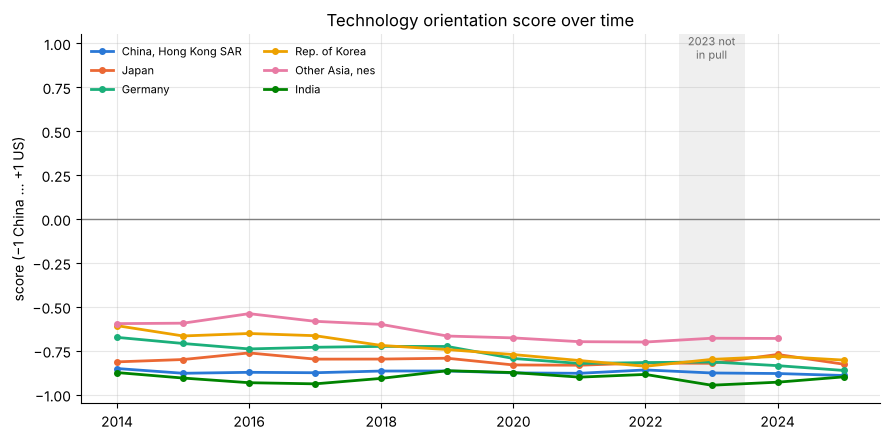

In [21]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for i, iso in enumerate(rep):
    d = combined[combined.country_iso3 == iso].sort_values("year")
    y = d["tech_orientation_score"] if has_scores else d["china_tech_imports_reported"] / 1e9
    ax.plot(d["year"], y, marker="o", ms=4, color=SERIES[i], label=d["country"].iat[0])
if has_scores:
    ax.set_ylim(-1.05, 1.05); ax.axhline(0, color="grey", lw=1)
    ax.set_title("Technology orientation score over time")
    ax.set_ylabel("score (−1 China … +1 US)")
else:
    ax.set_title("QA fallback — score unavailable (no US partner data)\nImports of HS 8471/8517/8541/8542 from China")
    ax.set_ylabel("US$ billion")
ax.axvspan(2022.5, 2023.5, color="grey", alpha=0.12, lw=0)
ax.text(2023, ax.get_ylim()[1], "2023 not\nin pull", ha="center", va="top", fontsize=8, color="dimgray")
ax.legend(frameon=False, fontsize=8, ncol=2)
fig.tight_layout(); fig.savefig(FIG / "tech_qa_1_timeseries.png", dpi=130); plt.show()

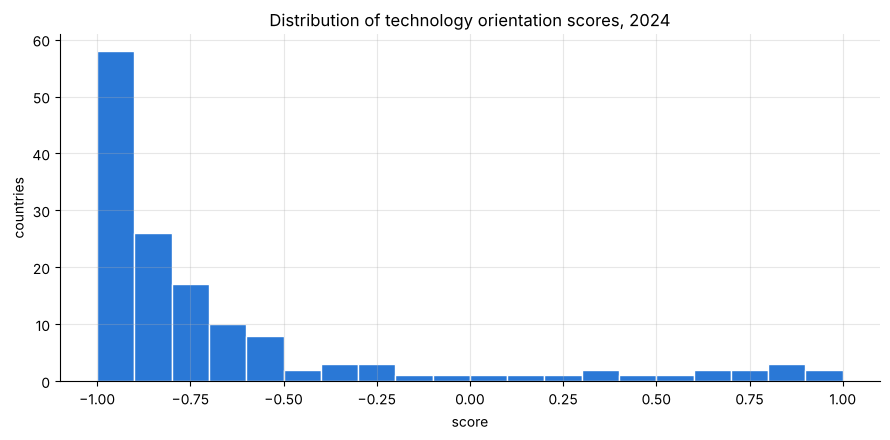

In [22]:
scored_years = combined.loc[combined.tech_orientation_score.notna(), "year"]
fig, ax = plt.subplots(figsize=(9, 4.5))
if has_scores:
    latest = int(scored_years.value_counts().loc[lambda s: s >= s.max() * 0.8].index.max())
    combined.loc[combined.year == latest, "tech_orientation_score"].hist(
        bins=np.linspace(-1, 1, 21), ax=ax, color=SERIES[0], edgecolor="white")
    ax.set_title(f"Distribution of technology orientation scores, {latest}")
    ax.set_xlabel("score"); ax.set_ylabel("countries")
else:
    status = combined.pivot_table(index="year", columns="data_status", values="country_iso3",
                                  aggfunc="count", fill_value=0)
    palette = {"complete": "#1baf7a", "partial_basket": "#eda100", "missing_us": "#eb6834",
               "missing_china": "#e87ba4", "no_data": "#c3c2b7", "year_not_in_source_pull": "#8a8a85"}
    order = [c for c in palette if c in status]
    status[order].plot(kind="bar", stacked=True, ax=ax, width=0.8, edgecolor="white",
                       color=[palette[c] for c in order])
    ax.set_title("QA fallback — no scores to distribute\nCountry-year data status by year")
    ax.set_ylabel("countries"); ax.legend(frameon=False, fontsize=8, title=None)
fig.tight_layout(); fig.savefig(FIG / "tech_qa_2_distribution.png", dpi=130); plt.show()

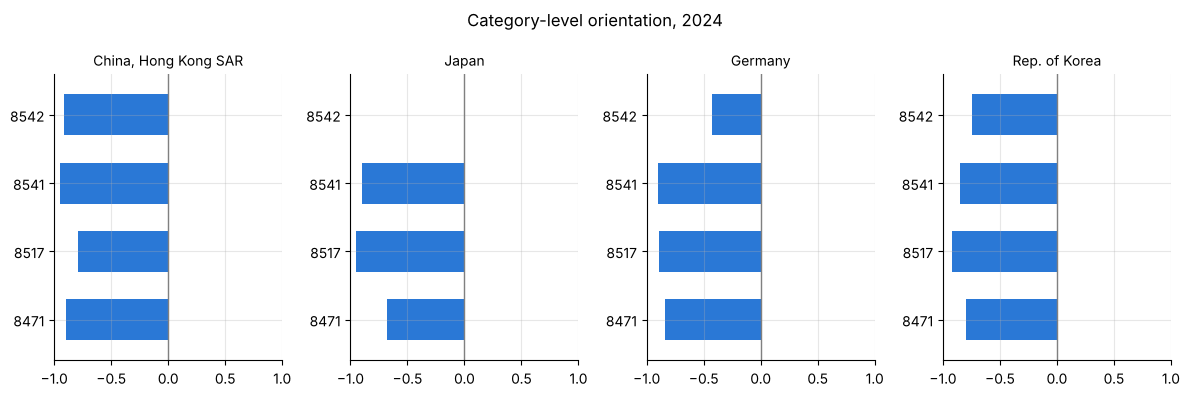

In [23]:
latest_cn = int(components.loc[components.china_imports.notna(), "year"]
                 .value_counts().loc[lambda s: s >= s.max() * 0.8].index.max())
sel = rep[:4]
sub = components[(components.year == latest_cn) & components.country_iso3.isin(sel)]
fig, axes = plt.subplots(1, len(sel), figsize=(12, 4), sharey=not has_scores)
for ax, iso in zip(axes, sel):
    d = sub[sub.country_iso3 == iso].set_index("hs_code")
    if has_scores:
        d = d.reindex(list(tech.TECH_CATEGORIES))
        yv = np.arange(len(d)); sc = d["category_orientation_score"]
        ax.barh(yv, sc.fillna(0).where(sc.notna()), color=SERIES[0], height=0.6)
        for yi, v in zip(yv, sc):
            if pd.isna(v): ax.text(0.05, yi, "n/a (missing)", va="center", fontsize=8, color="dimgray")
        ax.set_yticks(yv, d.index); ax.set_ylim(-0.6, len(d) - 0.4); ax.set_xlim(-1, 1); ax.axvline(0, color="grey", lw=1)
    else:
        x = np.arange(len(d)); w = 0.38
        ax.bar(x, d["china_imports"] / 1e9, 0.6, color=SERIES[1], label="China")  # US side missing: not drawn as zero
        ax.set_xticks(x, d.index)
    ax.set_title(d["country"].iat[0], fontsize=10)
axes[0].set_ylabel("US$ billion" if not has_scores else "")
fig.suptitle(f"Category-level {'orientation' if has_scores else 'imports from China (US side missing)'}, {latest_cn}")
fig.tight_layout(); fig.savefig(FIG / "tech_qa_3_categories.png", dpi=130); plt.show()

## Final checks

In [24]:
checks = {
    "all ZIPs loaded": summary["zip_files"] == len(tech.discover_zip_files(RAW_DIR)) == summary["data_files_loaded"],
    "no batch omitted (every ZIP contributes rows)": (inventory["rows"] > 0).all(),
    "no duplicates from overlapping ZIPs": not deduped.duplicated(key).any(),
    "bilateral US/China columns preserved": {"china_imports", "us_imports"} <= set(components.columns),
    "scores bounded in [-1, 1]": combined.tech_orientation_score.dropna().between(-1, 1).all(),
    "missing never scored (not treated as neutral)": combined.loc[combined.data_status.isin(
        ["missing_us", "missing_china", "no_data", "year_not_in_source_pull"]), "tech_orientation_score"].isna().all(),
    "partner-missing rows have NaN, not 0, for the absent side":
        components.loc[components.data_status == "missing_us", "us_imports"].isna().all(),
    "US partner data present": summary["partner_codes"].count(str(tech.US_CODE)) > 0,
}
pd.Series(checks, name="pass").to_frame()

,pass
all ZIPs loaded,True
no batch omitted (every ZIP contributes rows),True
no duplicates from overlapping ZIPs,True
bilateral US/China columns preserved,True
"scores bounded in [-1, 1]",True
missing never scored (not treated as neutral),True
"partner-missing rows have NaN, not 0, for the absent side",True
US partner data present,True


**`US partner data present` = False is the one blocking issue.** Add the partner-842 batches for the same years and HS codes (plus 2023 for both partners) to `data/raw/un_comtrade/technology/` and re-run this notebook. No code changes are needed.